# Study results — quick look

Three blocks of plots: local models, OpenAI models, and both combined (filtered to the case both share).

Regenerate the source CSV with:
```
uv run nli-eval aggregate --manifest dataset/manifest.yaml --csv study/runs/summary.csv --json study/runs/summary.json
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

CSV_PATH = Path("runs/summary.csv")
df = pd.read_csv(CSV_PATH)
df["total_tokens"] = df["total_input_tokens"] + df["total_output_tokens"]
df["latency_s"] = df["total_latency_ms"] / 1000.0

PROMPT_ORDER = ["poor", "medium", "rich"]
print(f"{len(df)} rows loaded from {CSV_PATH}")
df.head()

69 rows loaded from runs/summary.csv


,source,model,case_id,prompt_key,run,workflow_complete,n_turns,n_llm_calls,n_tool_rounds,n_tool_calls,n_failed_tool_calls,tool_failure_rate,total_input_tokens,total_output_tokens,total_latency_ms,hm_f1,hm_precision,hm_recall,total_tokens,latency_s
0,local_models,deepseek-r1-8b,001_diary_study,medium,1,False,0,0,0,0,0,0.0,0,0,0.0,NaN,NaN,NaN,0,0.0
1,local_models,deepseek-r1-8b,001_diary_study,poor,1,False,0,0,0,0,0,0.0,0,0,0.0,NaN,NaN,NaN,0,0.0
2,local_models,deepseek-r1-8b,001_diary_study,rich,1,False,0,0,0,0,0,0.0,0,0,0.0,NaN,NaN,NaN,0,0.0
3,local_models,deepseek-r1-8b,002_diary_study,medium,1,False,0,0,0,0,0,0.0,0,0,0.0,NaN,NaN,NaN,0,0.0
4,local_models,deepseek-r1-8b,002_diary_study,poor,1,False,0,0,0,0,0,0.0,0,0,0.0,NaN,NaN,NaN,0,0.0


In [2]:
def plot_block(sub_df: pd.DataFrame, title: str) -> None:
    """Render the four standard plots for one slice of the data."""
    if sub_df.empty:
        print(f"[skip] {title}: no rows")
        return

    model_order = sorted(sub_df["model"].unique())
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(title, fontsize=15, fontweight="bold")

    # HashMatch F1 (only completed runs contribute; nulls are dropped by seaborn)
    sns.barplot(
        data=sub_df,
        x="model",
        y="hm_f1",
        hue="prompt_key",
        hue_order=PROMPT_ORDER,
        order=model_order,
        ax=axes[0][0],
        errorbar=None,
    )
    axes[0][0].set_title("HashMatch F1 (higher = better)")
    axes[0][0].set_ylim(0, 1)
    axes[0][0].set_ylabel("F1")

    # Completion rate (fraction of runs where workflow_complete=True)
    completion = (
        sub_df.groupby(["model", "prompt_key"])["workflow_complete"]
        .mean()
        .reset_index()
    )
    sns.barplot(
        data=completion,
        x="model",
        y="workflow_complete",
        hue="prompt_key",
        hue_order=PROMPT_ORDER,
        order=model_order,
        ax=axes[0][1],
    )
    axes[0][1].set_title("Completion rate (workflow_complete)")
    axes[0][1].set_ylim(0, 1)
    axes[0][1].set_ylabel("fraction completed")

    # Total tokens (in + out)
    sns.barplot(
        data=sub_df,
        x="model",
        y="total_tokens",
        hue="prompt_key",
        hue_order=PROMPT_ORDER,
        order=model_order,
        ax=axes[1][0],
        errorbar=None,
    )
    axes[1][0].set_title("Total tokens (input + output)")
    axes[1][0].set_ylabel("tokens")

    # Latency (seconds)
    sns.barplot(
        data=sub_df,
        x="model",
        y="latency_s",
        hue="prompt_key",
        hue_order=PROMPT_ORDER,
        order=model_order,
        ax=axes[1][1],
        errorbar=None,
    )
    axes[1][1].set_title("Wall-clock latency")
    axes[1][1].set_ylabel("seconds")

    for ax in axes.flat:
        ax.tick_params(axis="x", rotation=30)
        for label in ax.get_xticklabels():
            label.set_horizontalalignment("right")

    plt.tight_layout()
    plt.show()

## 1. Local models
All three cases (`001_diary_study`, `002_diary_study`, `003_cardio_wellness`) averaged per (model, prompt).

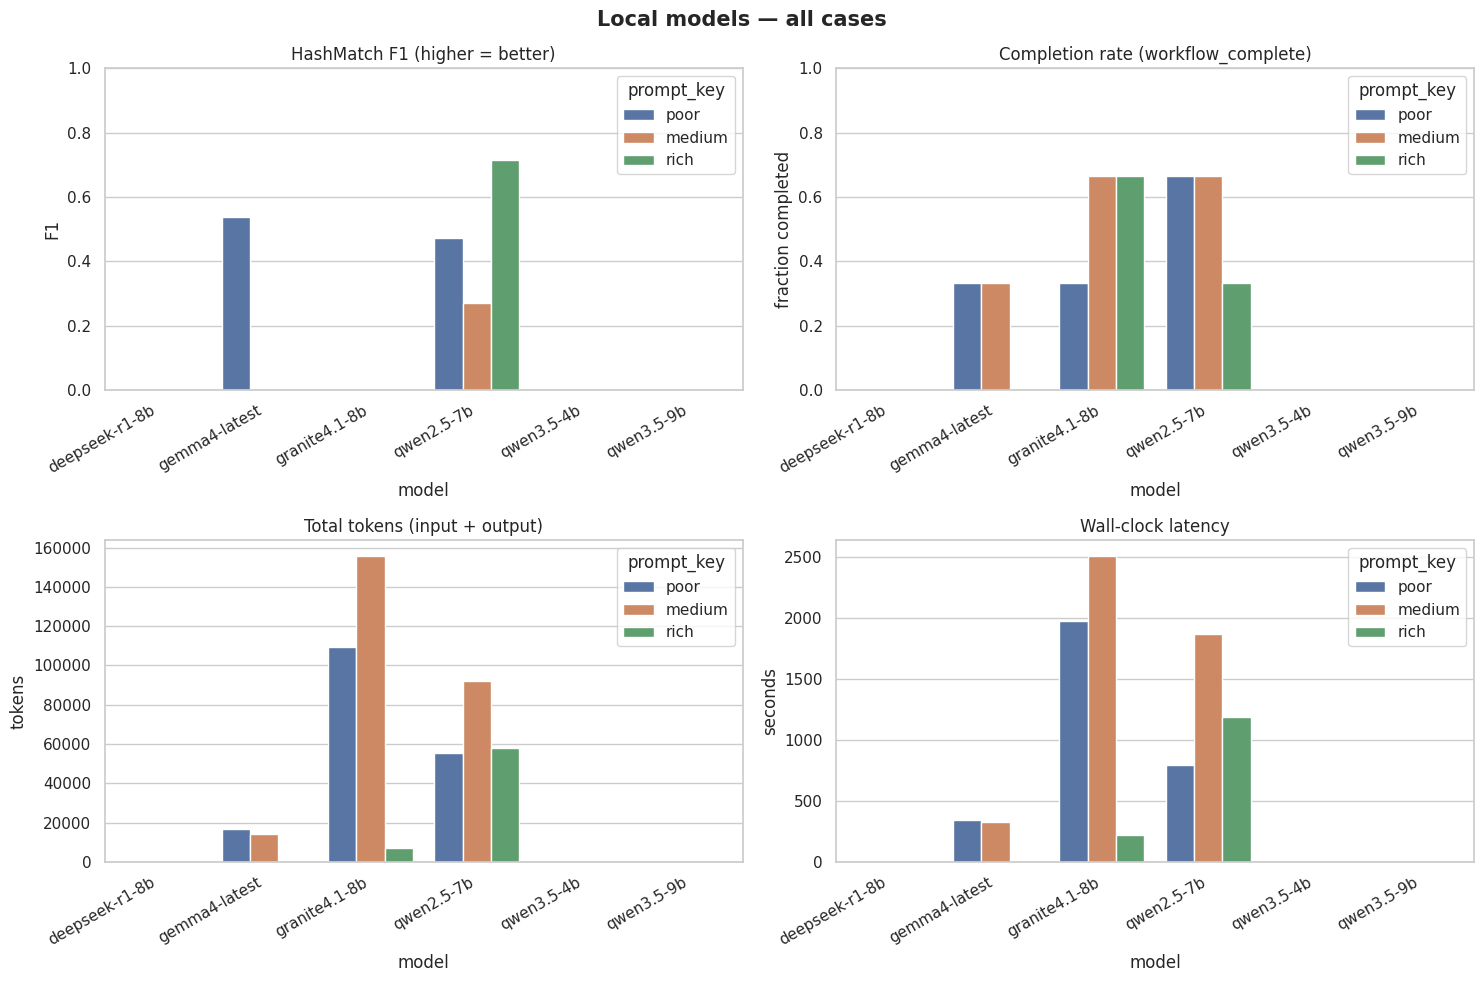

In [3]:
plot_block(df[df["source"] == "local_models"], "Local models — all cases")

### 1a. Per-case zoom (local models)
Same four metrics, but one plot block per case so per-case differences aren't averaged out.

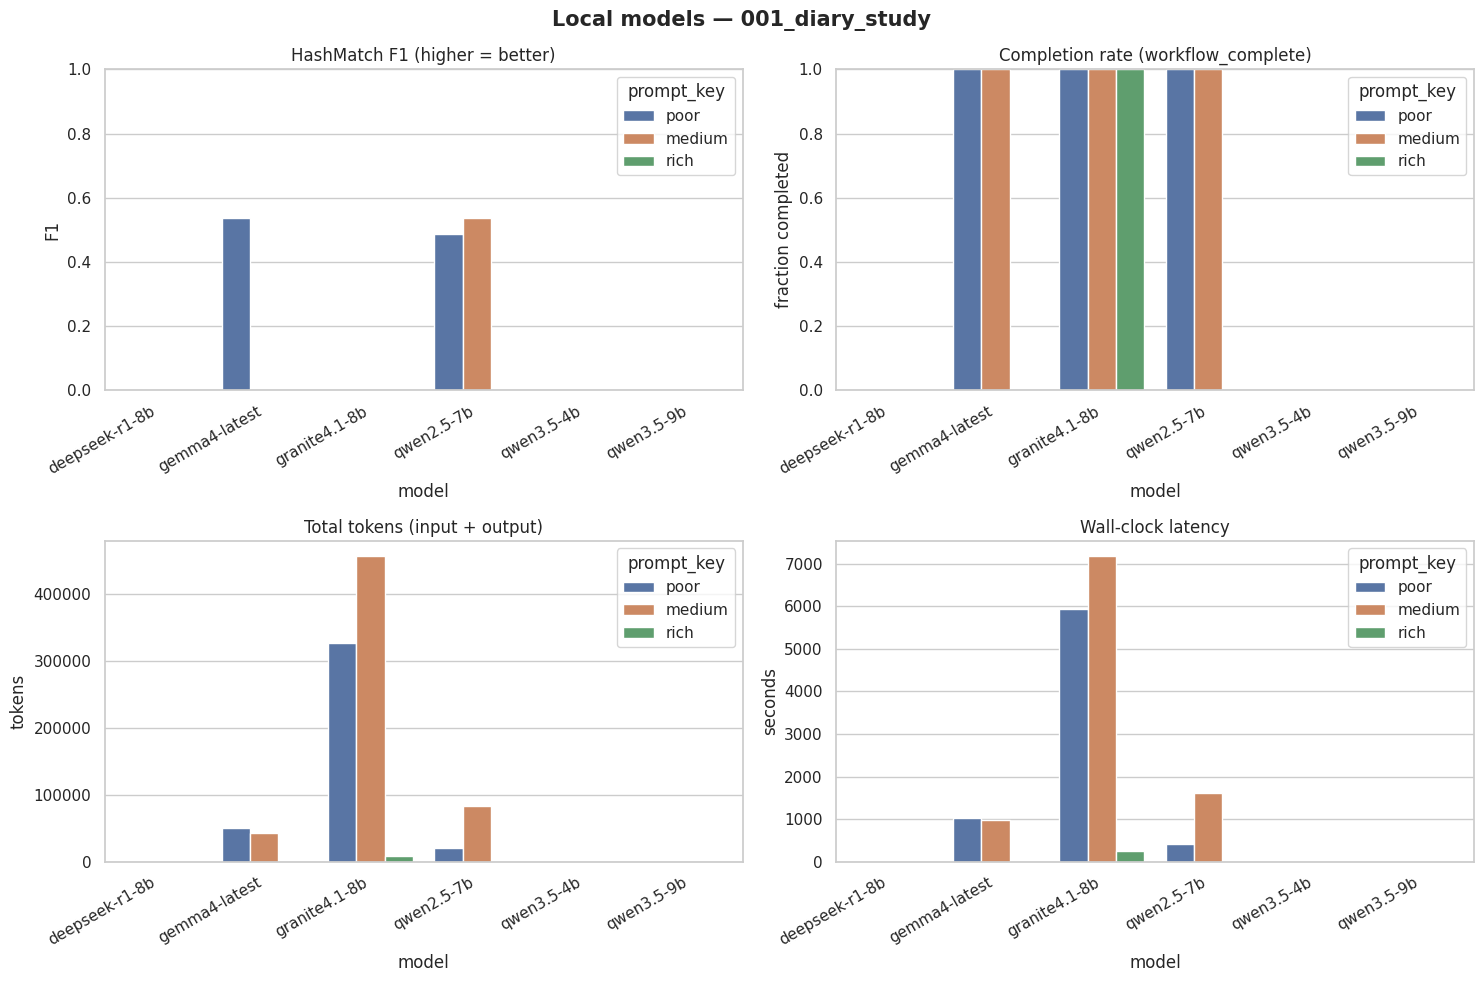

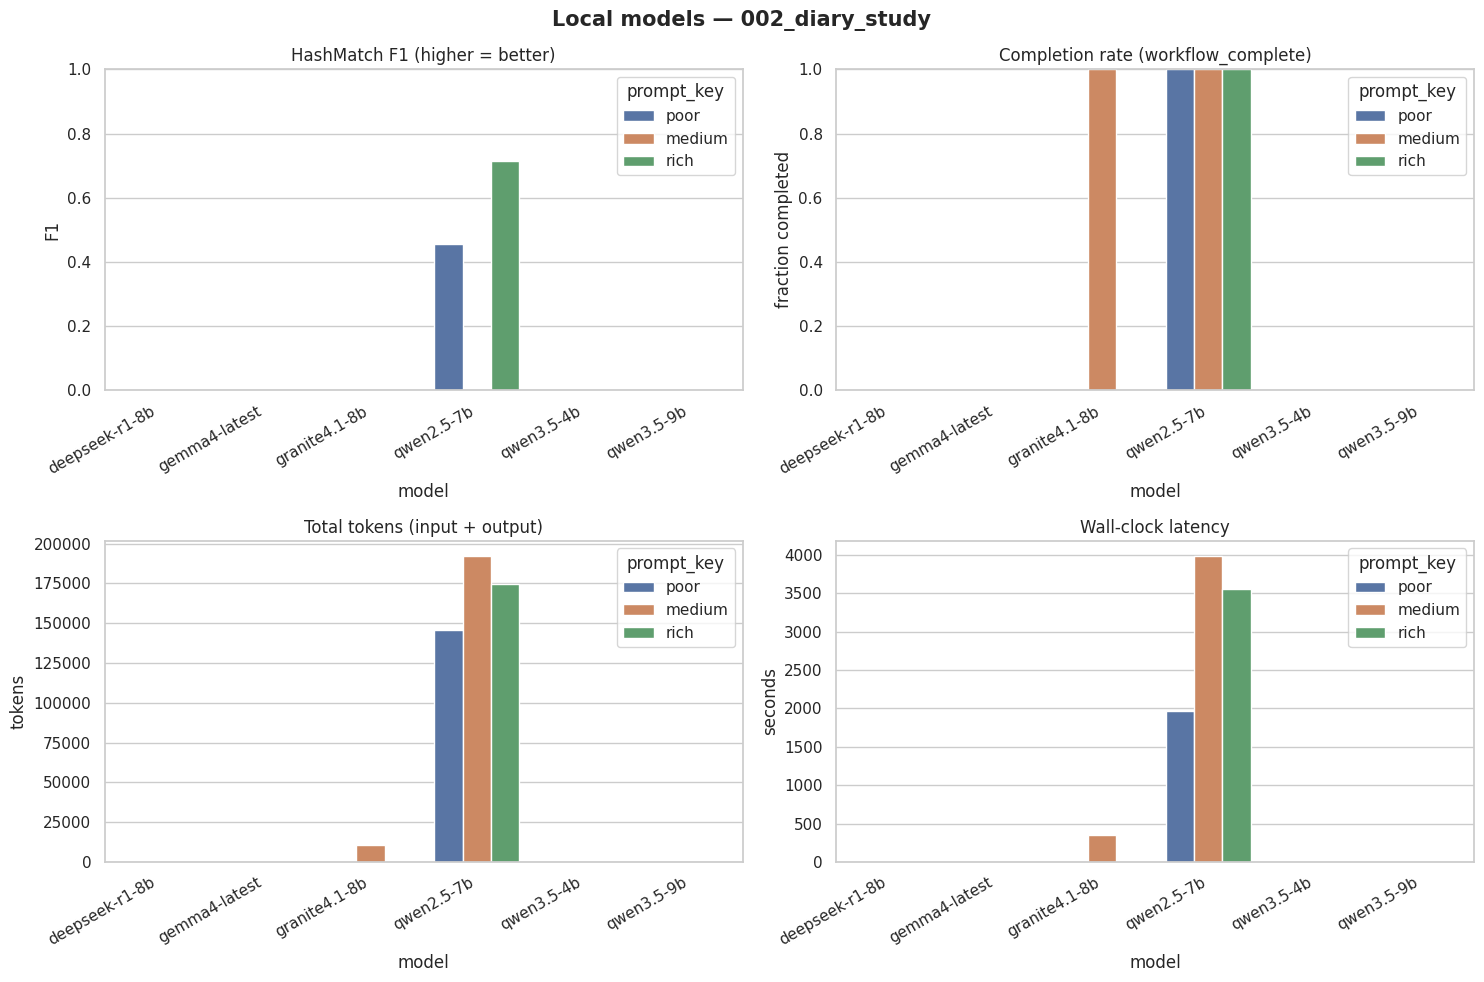

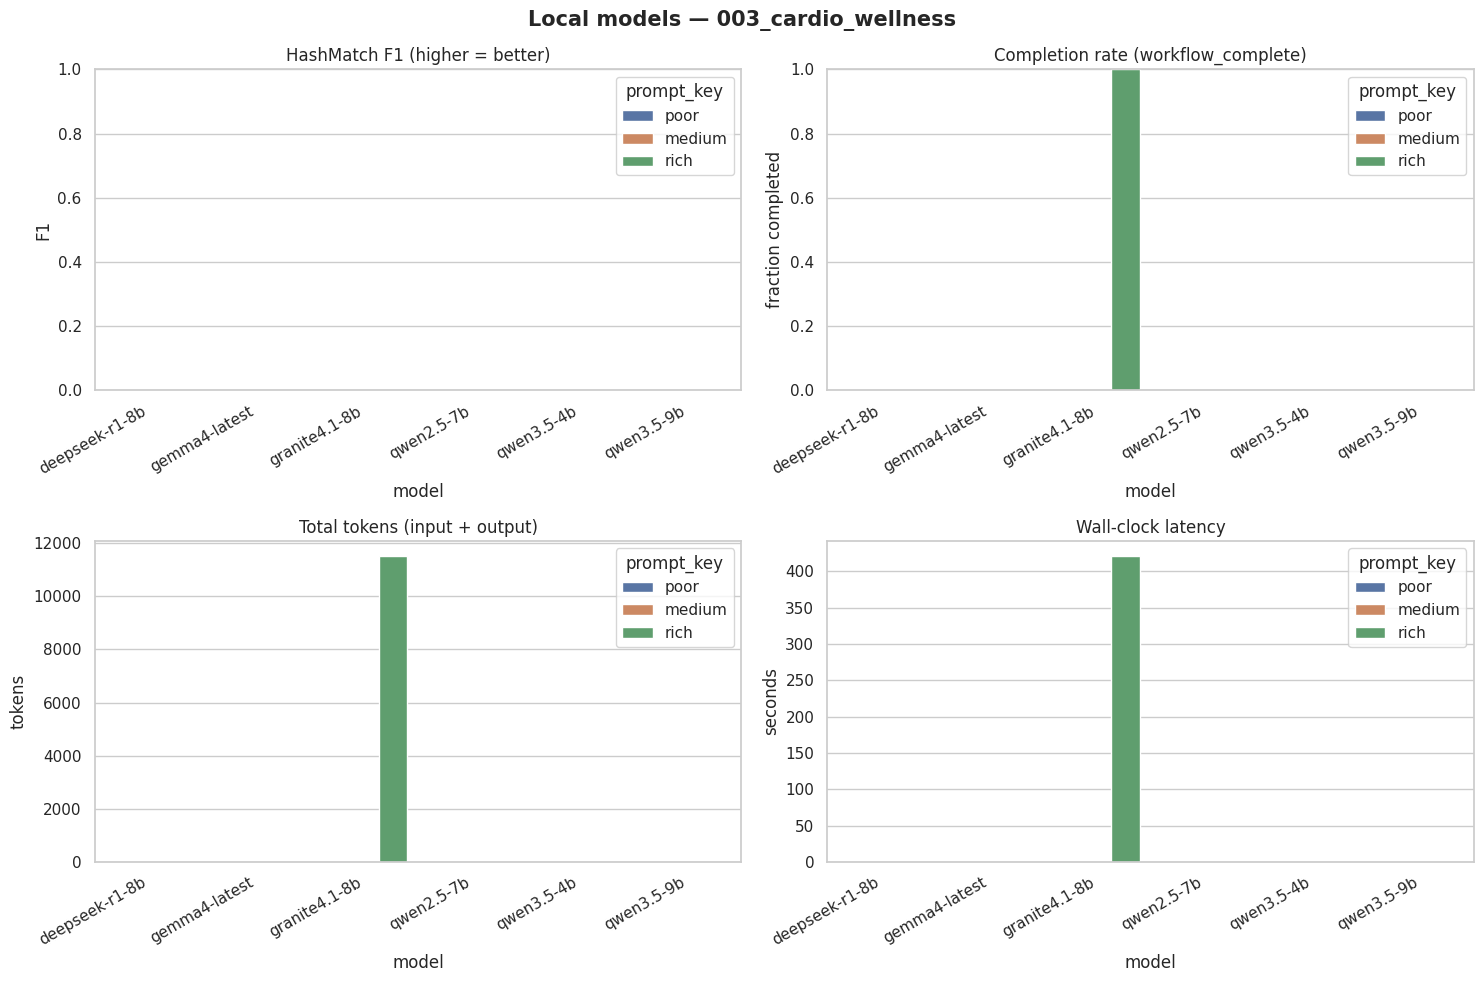

In [4]:
local_df = df[df["source"] == "local_models"]
for case_id in sorted(local_df["case_id"].unique()):
    plot_block(local_df[local_df["case_id"] == case_id], f"Local models — {case_id}")

## 2. OpenAI models
Only `003_cardio_wellness` was run for the OpenAI batch.

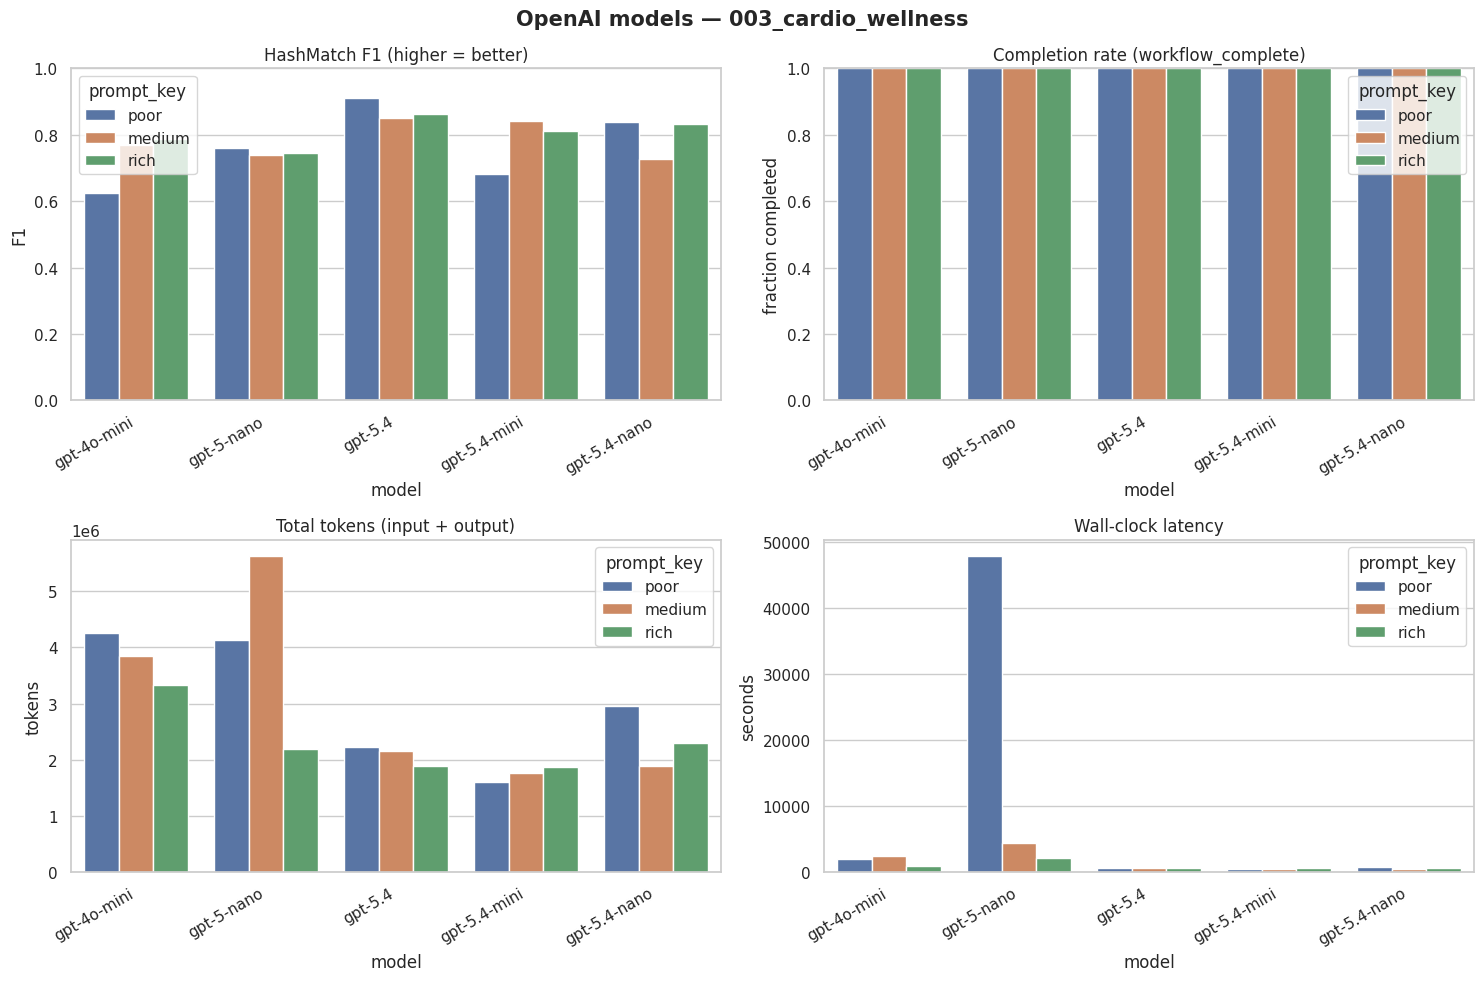

In [5]:
plot_block(df[df["source"] == "models"], "OpenAI models — 003_cardio_wellness")

## 3. Combined — OpenAI + local on the same case
Filtered to `003_cardio_wellness` so the comparison is fair (only case both batches share).

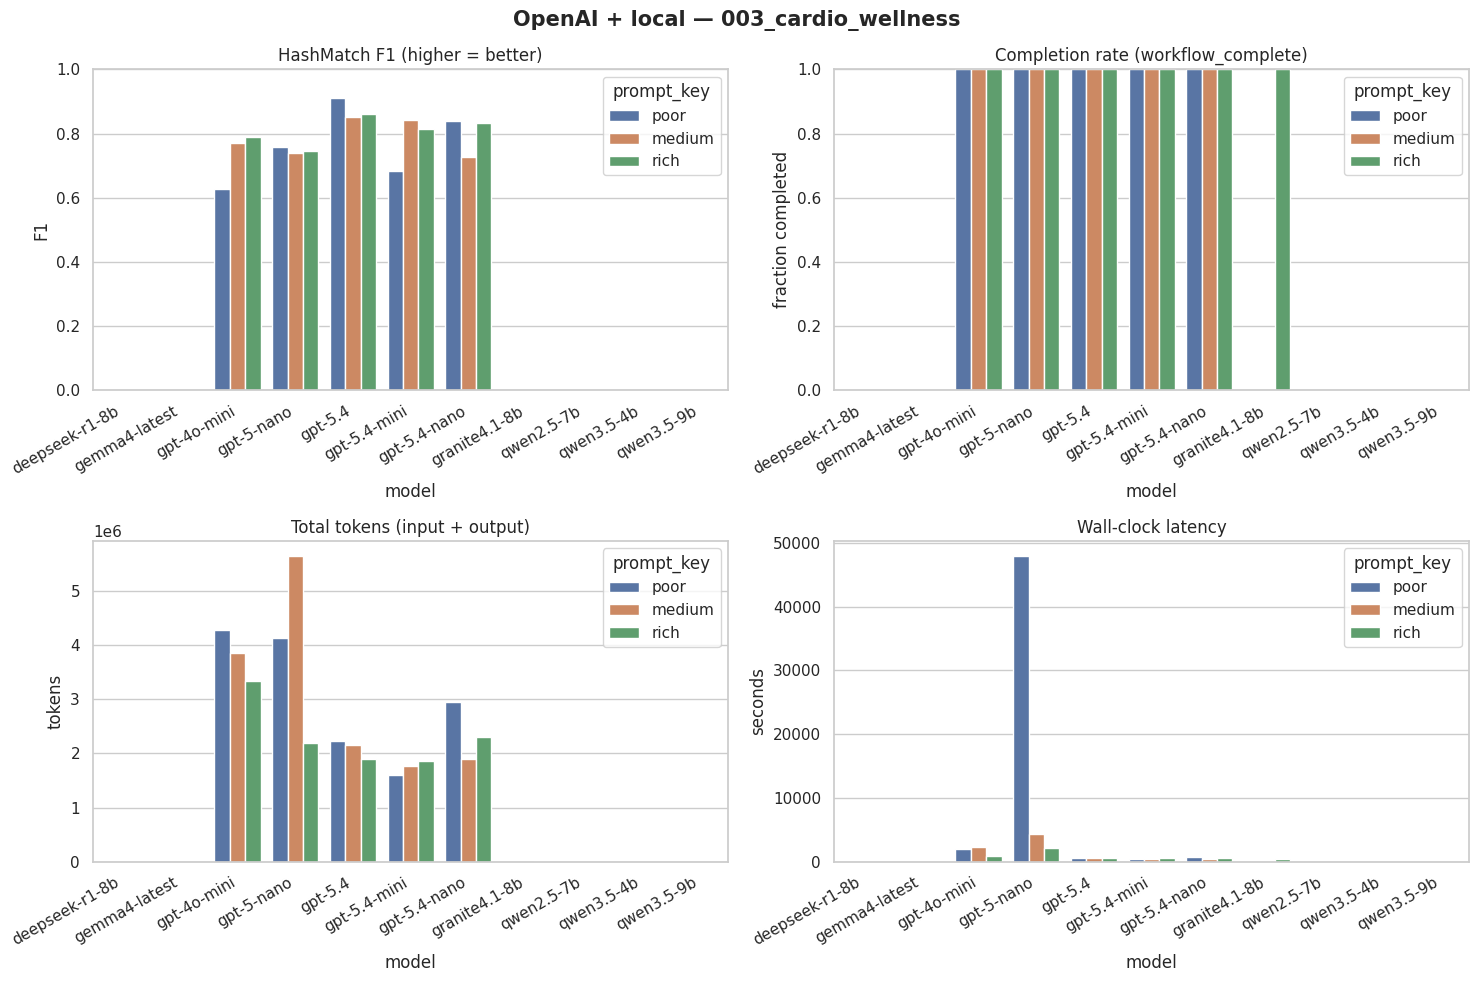

In [6]:
plot_block(
    df[df["case_id"] == "003_cardio_wellness"],
    "OpenAI + local — 003_cardio_wellness",
)